# 06 · Réplica del paper 2 (Donizette, Rocco y de Queiroz, 2025)

Grupo 4 · Leishmaniosis cutánea en Cajamarca

El paper 2 predice los casos mensuales de leishmaniasis con redes feedforward (SFNN y DFNN), LSTM y SVR.
Aquí se implementan **SFNN1, SFNN2 y DFNN** (`src/modelo_paper2.py`) sobre los datos de Cajamarca y se
comparan con los cinco modelos del equipo (`02_modelos.ipynb`) bajo el mismo protocolo.

Se conserva del paper: capas densas, Dropout 0,2, salida lineal, MinMaxScaler, pérdida MSE y la cuadrícula
(neuronas, ReLU/Tanh, Adam/RMSprop, 100/300 épocas), eligiendo por RMSE. Diferencias: elección por validación
temporal (no `GridSearchCV` de 5 folds), cuadrícula de neuronas reducida, 4 conjuntos de variables (no las 127
combinaciones), clima rezagado, PyTorch en vez de Keras, y sin LSTM ni SVR (fuera del temario). Detalle en
`results/analisis/ANALISIS_PAPER2.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display

import comparacion_final as cf
import modelo_paper2 as p2

pd.set_option("display.width", 200)

## 1. Arquitecturas replicadas

In [2]:
base = dict(neurons=12, activation="relu", optimizer="adam", epochs=100)
print("SFNN (1 capa oculta, Dropout 0,2, salida lineal):")
print(p2.FeedForward(n_hidden=1, **base)._build(7))
print()
print("DFNN (2 capas ocultas):")
print(p2.FeedForward(n_hidden=2, **base)._build(7))

SFNN (1 capa oculta, Dropout 0,2, salida lineal):
Sequential(
  (0): Linear(in_features=7, out_features=12, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=12, out_features=1, bias=True)
)

DFNN (2 capas ocultas):
Sequential(
  (0): Linear(in_features=7, out_features=12, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=12, out_features=12, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=12, out_features=1, bias=True)
)


## 2. Entrenamiento

`RUN_EXPERIMENT = True` reentrena las 3 redes × 4 conjuntos de variables × 2 protocolos (≈1 h con 2 hilos por
protocolo) y regenera `results/paper2*/` y `results/comparacion_final/`. Por defecto solo se leen los resultados
guardados.

In [3]:
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    import torch
    from threadpoolctl import threadpool_limits
    torch.set_num_threads(2)
    with threadpool_limits(limits=2):
        p2.main("oficial", ROOT / "results/paper2")
        p2.main("historico", ROOT / "results/paper2_historico")
    cf.main()

## 3. Conjuntos de variables

| Conjunto | Variables |
|---|---|
| `casos3` | `lag1`, `lag2`, `lag3` (como el paper) |
| `casos7` | las 7 variables de casos del equipo (misma entrada que los demás modelos) |
| `casos3_clima`, `casos7_clima` | lo anterior más 9 rezagos de lluvia, tmax y tmin |

In [4]:
for name, cols in p2.FEATURE_SETS.items():
    print(f"{name:13} ({len(cols):2} variables)", cols[:7], "..." if len(cols) > 7 else "")

casos3        ( 3 variables) ['lag1', 'lag2', 'lag3'] 
casos3_clima  (12 variables) ['lag1', 'lag2', 'lag3', 'pp_total_mm_lag1', 'pp_total_mm_lag2', 'pp_total_mm_lag3', 'tmax_media_lag1'] ...
casos7        ( 7 variables) ['lag1', 'lag2', 'lag3', 'lag12', 'media3', 'mes_sin', 'mes_cos'] 
casos7_clima  (16 variables) ['lag1', 'lag2', 'lag3', 'lag12', 'media3', 'mes_sin', 'mes_cos'] ...


## 4. Resultados, protocolo oficial (prueba 2019-2024)

In [5]:
oficial = pd.read_csv(ROOT / "results/comparacion_final/metricas_oficial.csv")
reg = ["origen", "modelo", "entradas", "RMSE_validacion", "RMSE", "RMSE_media_semillas", "RMSE_sd_semillas", "MAE", "MASE"]
display(oficial.sort_values("RMSE")[reg].round(3).reset_index(drop=True))

,origen,modelo,entradas,RMSE_validacion,RMSE,RMSE_media_semillas,RMSE_sd_semillas,MAE,MASE
0,Paper 2,DFNN,Casos (7) + clima,1.115,0.916,0.922,0.016,0.602,0.585
1,Paper 2,DFNN,Solo casos (7),1.115,0.916,0.922,0.016,0.602,0.585
2,Equipo,MLP,Solo casos (7),1.131,0.922,NaN,NaN,0.575,0.559
3,Equipo,MLP,Casos (7) + clima,1.131,0.922,NaN,NaN,0.575,0.559
4,Equipo,Random Forest,Solo casos (7),1.127,0.926,NaN,NaN,0.598,0.581
5,Equipo,Random Forest,Casos (7) + clima,1.127,0.926,NaN,NaN,0.598,0.581
6,Equipo,CNN temporal,Casos (7) + clima,1.128,0.938,NaN,NaN,0.621,0.604
7,Equipo,CNN temporal,Solo casos (7),1.128,0.938,NaN,NaN,0.621,0.604
8,Equipo,Ridge / logística,Casos (7) + clima,1.129,0.940,NaN,NaN,0.583,0.567
9,Equipo,Ridge / logística,Solo casos (7),1.129,0.940,NaN,NaN,0.583,0.567


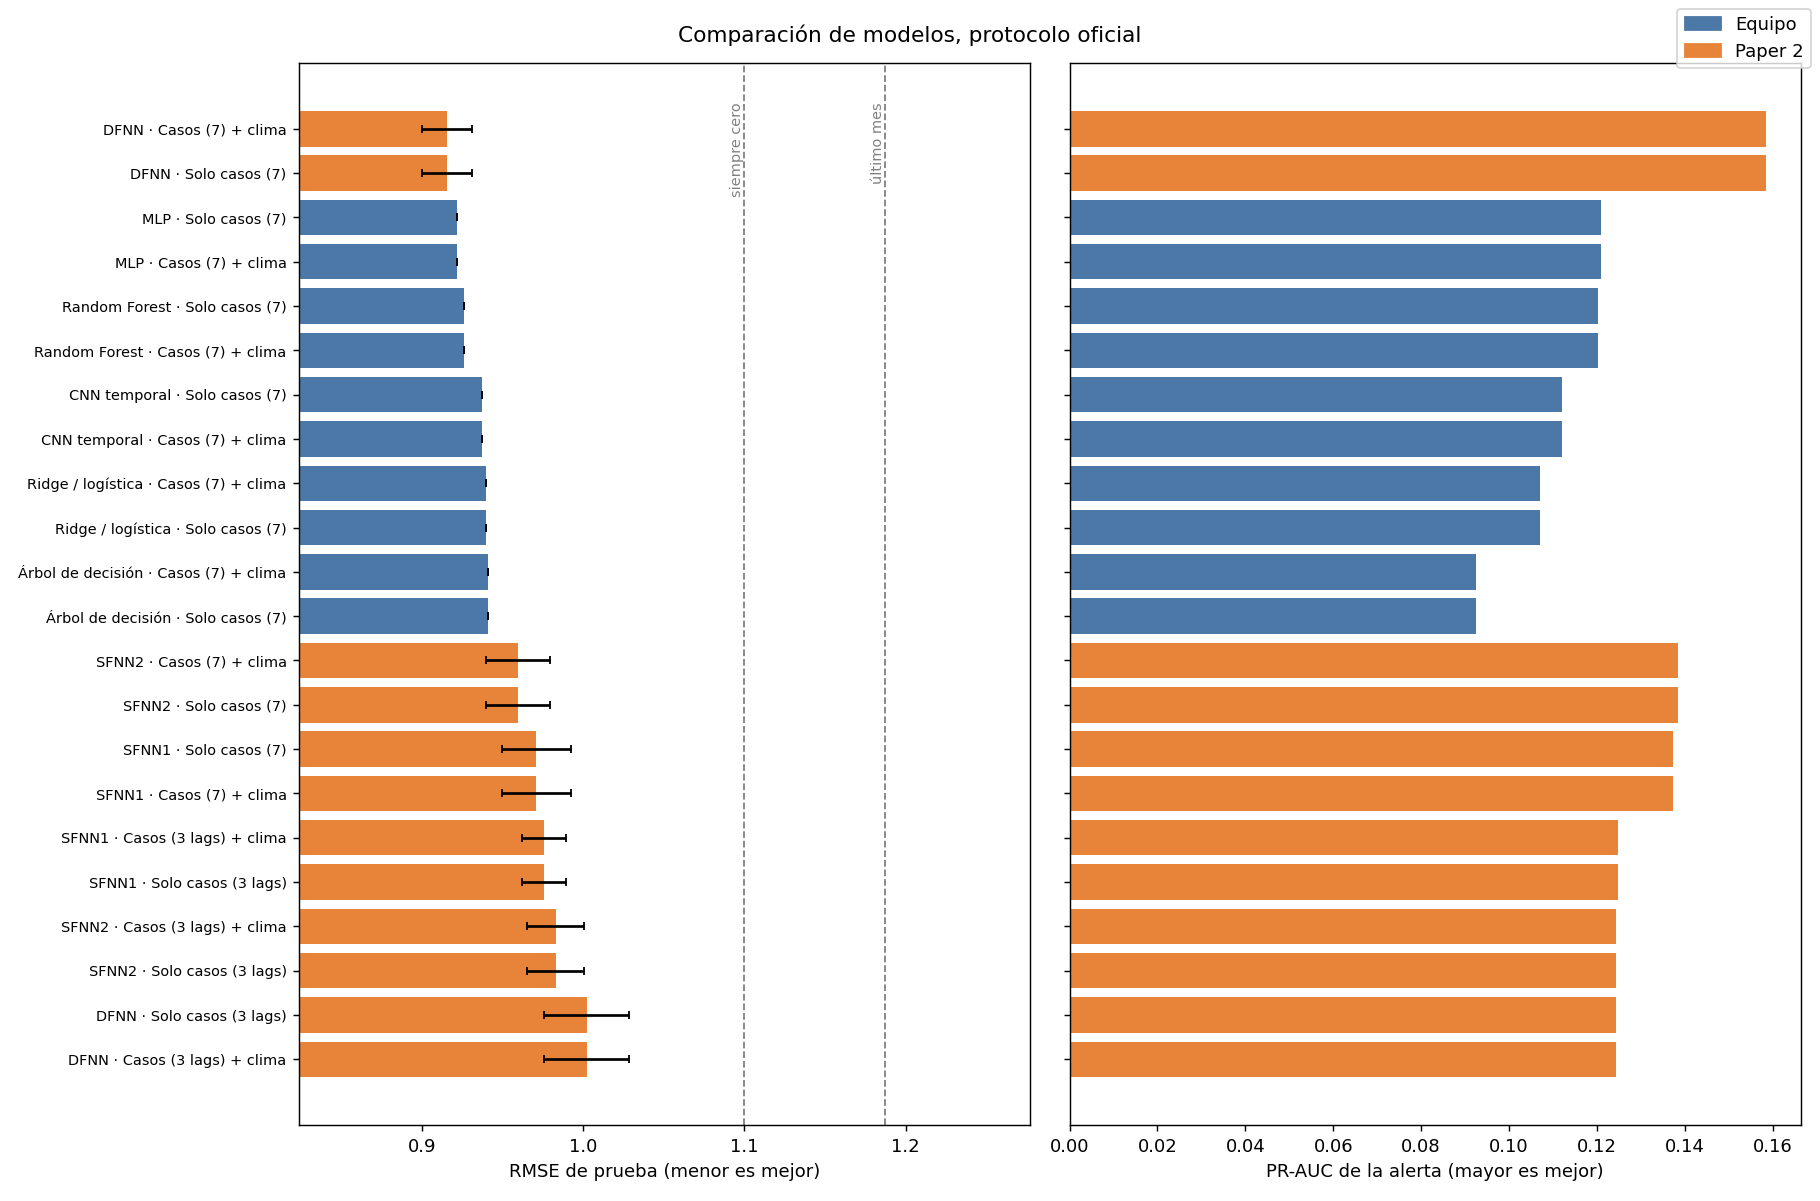

In [6]:
display(Image(str(ROOT / 'results/plots/comparacion_final_oficial.png')))

### Alerta (brote): accuracy, EER y matriz de confusión

In [7]:
al = ["origen", "modelo", "entradas", "PR_AUC", "ROC_AUC", "EER", "accuracy", "recall", "precision", "FPR", "F1", "TP", "FP", "FN", "TN"]
display(oficial[oficial.origen != "Referencia"].sort_values("PR_AUC", ascending=False)[al].round(3).reset_index(drop=True))

,origen,modelo,entradas,PR_AUC,ROC_AUC,EER,accuracy,recall,precision,FPR,F1,TP,FP,FN,TN
0,Paper 2,DFNN,Casos (7) + clima,0.158,0.796,0.259,0.826,0.583,0.095,0.167,0.164,70.0,664.0,50.0,3320.0
1,Paper 2,DFNN,Solo casos (7),0.158,0.796,0.259,0.826,0.583,0.095,0.167,0.164,70.0,664.0,50.0,3320.0
2,Paper 2,SFNN2,Solo casos (7),0.138,0.794,0.267,0.814,0.558,0.086,0.178,0.150,67.0,709.0,53.0,3275.0
3,Paper 2,SFNN2,Casos (7) + clima,0.138,0.794,0.267,0.814,0.558,0.086,0.178,0.150,67.0,709.0,53.0,3275.0
4,Paper 2,SFNN1,Solo casos (7),0.137,0.771,0.326,0.819,0.550,0.088,0.173,0.151,66.0,688.0,54.0,3296.0
5,Paper 2,SFNN1,Casos (7) + clima,0.137,0.771,0.326,0.819,0.550,0.088,0.173,0.151,66.0,688.0,54.0,3296.0
6,Paper 2,SFNN1,Casos (3 lags) + clima,0.125,0.727,0.316,0.779,0.600,0.077,0.215,0.137,72.0,858.0,48.0,3126.0
7,Paper 2,SFNN1,Solo casos (3 lags),0.125,0.727,0.316,0.779,0.600,0.077,0.215,0.137,72.0,858.0,48.0,3126.0
8,Paper 2,SFNN2,Casos (3 lags) + clima,0.124,0.726,0.321,0.803,0.542,0.079,0.189,0.138,65.0,754.0,55.0,3230.0
9,Paper 2,SFNN2,Solo casos (3 lags),0.124,0.726,0.321,0.803,0.542,0.079,0.189,0.138,65.0,754.0,55.0,3230.0


El *accuracy* engaña con ~3 % de alertas: la regla «nunca alertar» ya obtiene 97,1 %. Por eso se elige con RMSE
(casos) y PR-AUC/EER (alerta). EER es la tasa de error donde las falsas alarmas igualan a los brotes no detectados.

## 5. Resultados, protocolo histórico (prueba 2012-2014, clima observado)

In [8]:
hist = pd.read_csv(ROOT / "results/comparacion_final/metricas_historico.csv")
display(hist.sort_values("RMSE")[reg].round(3).reset_index(drop=True))

,origen,modelo,entradas,RMSE_validacion,RMSE,RMSE_media_semillas,RMSE_sd_semillas,MAE,MASE
0,Paper 2,DFNN,Solo casos (7),1.330,0.998,1.007,0.028,0.728,0.554
1,Equipo,CNN temporal,Solo casos (7),1.335,0.999,NaN,NaN,0.703,0.535
2,Equipo,Random Forest,Solo casos (7),1.329,1.016,NaN,NaN,0.718,0.547
3,Paper 2,SFNN1,Solo casos (7),1.347,1.016,1.020,0.011,0.750,0.570
4,Equipo,Árbol de decisión,Solo casos (7),1.394,1.016,NaN,NaN,0.722,0.549
5,Equipo,MLP,Solo casos (7),1.339,1.017,NaN,NaN,0.722,0.549
6,Equipo,CNN temporal,Casos (7) + clima,1.363,1.022,NaN,NaN,0.728,0.554
7,Paper 2,SFNN2,Solo casos (7),1.336,1.024,1.016,0.021,0.749,0.570
8,Paper 2,DFNN,Casos (7) + clima,1.352,1.024,1.032,0.018,0.757,0.576
9,Equipo,Random Forest,Casos (7) + clima,1.347,1.029,NaN,NaN,0.732,0.557


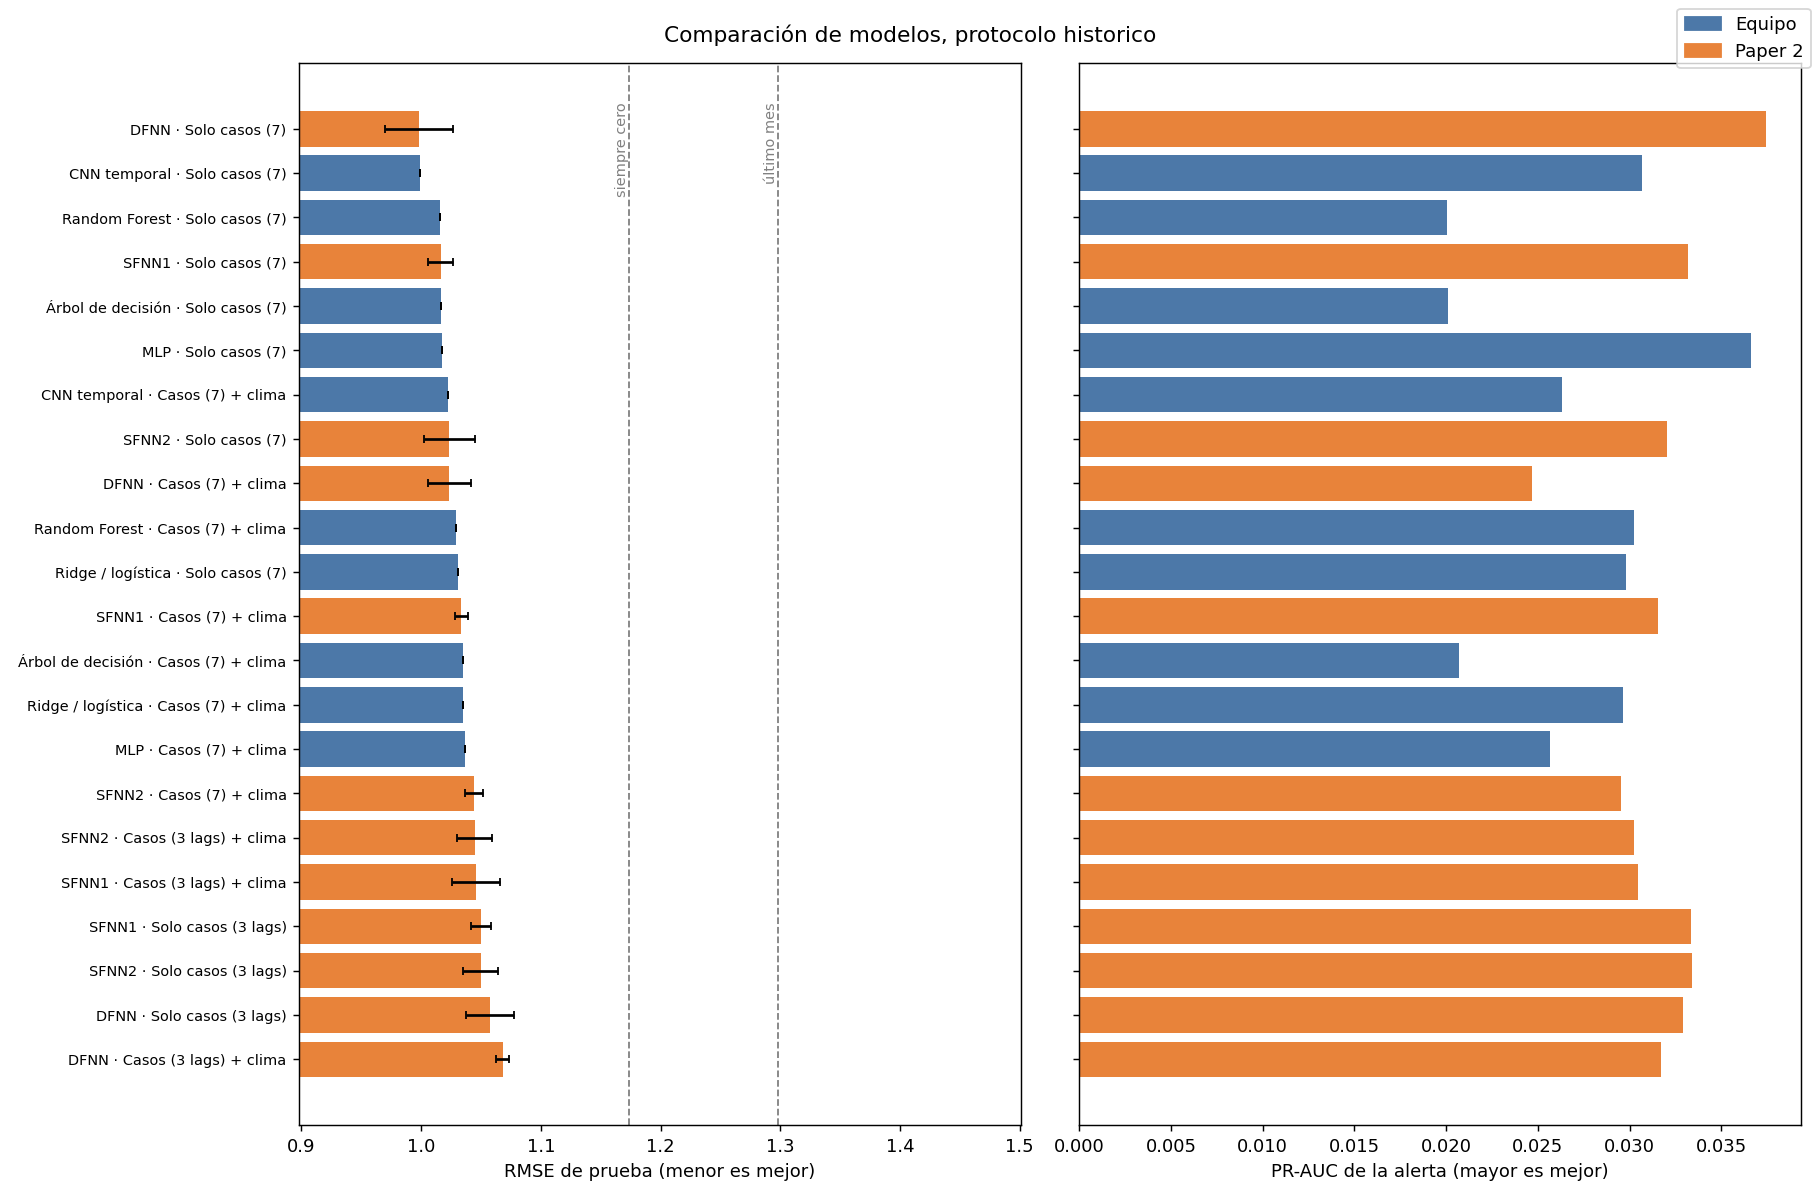

In [9]:
display(Image(str(ROOT / 'results/plots/comparacion_final_historico.png')))

## 6. Efecto del clima (media de 5 semillas en las redes del paper 2, protocolo histórico)

In [10]:
h = hist[hist.origen == "Paper 2"].copy()
h["conjunto"] = h.entradas.str.replace(" + clima", "", regex=False).str.replace("Solo casos", "Casos")
h["clima"] = h.entradas.str.contains("clima")
piv = h.pivot_table(index=["modelo", "conjunto"], columns="clima", values="RMSE_media_semillas")
piv.columns = ["sin clima", "con clima"]
piv["cambio (con − sin)"] = piv["con clima"] - piv["sin clima"]
display(piv.round(3))

sin clima  con clima  cambio (con − sin)
modelo conjunto                                                
DFNN   Casos (3 lags)      1.047      1.060               0.013
       Casos (7)           1.007      1.032               0.025
SFNN1  Casos (3 lags)      1.050      1.067               0.017
       Casos (7)           1.020      1.035               0.015
SFNN2  Casos (3 lags)      1.046      1.061               0.015
       Casos (7)           1.016      1.037               0.021

## Conclusiones

- **Oficial:** la DFNN con las 7 variables de casos obtiene el menor RMSE de validación y de prueba (0,916 con la
  semilla 42; **0,922 ± 0,016** con 5 semillas), pero queda **empatada** con la MLP (0,922) y el Random Forest (0,926):
  la diferencia es menor que la variación entre semillas. En la alerta sí queda por delante (PR-AUC 0,158 y EER 0,259
  frente a 0,121 y 0,301 de la MLP), aunque con una sola semilla.
- **Entradas:** con solo `lag1`–`lag3` las redes del paper rinden peor (≈0,955) que con las 7 variables (≈0,92–0,94).
  Gran parte de la brecha con los modelos del equipo se debe a las entradas, no a la arquitectura.
- **Arquitectura:** con 3 variables, la más simple (SFNN1) iguala a las demás; con 7, la más profunda (DFNN) es la mejor.
- **Clima:** no mejora, ni siquiera con clima observado (histórico): el RMSE medio empeora 0,01–0,03 en las seis
  combinaciones. En el oficial no hay clima observado (SENAMHI termina en octubre de 2015).
- **Todos superan** a las reglas simples en RMSE, pero «siempre cero» (0,432) sigue ganando en MAE.